### *Map Reduce*
- Map reduce operations are essential for efficient tast decomposition and parallel processing.It has two phases 
- `Map`- Break the task into smaller sub-tasks,processing each sub-task in parallel
- `Reduce` - Aggregate the the results across all the completed sub-tasks 
  

In [1]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..")))
import operator
from typing import Annotated, TypedDict, cast

from IPython.display import Image, display
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send

# from langchain_core.messages import HumanMessage, SystemMessage
# from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel

from utils.utils import Models, Trace, get_invoke_options


In [5]:
trace = Trace()
model = Models()
grod_llm = model.create_groq_model()
nvidia_model = model.create_nvidia_model()
invoke_options = get_invoke_options()


d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\_common.py:269: UserWarning: Found nvidia/nemotron-3.5-bolt-e4b in available_models, but type is unknown and inference may fail.
  warnings.warn(


In [6]:
subject_prompt = (
    """Generate a comma serpated list of 3 to 5 examples related to the {topic}"""
)
joke_prompt = """Generate a witty and really funny joke about the {subject}"""
best_joke_prompt = """below are the list of jokes on the {topic}.select the best one from the list and return the ID of the best joke, starting the ID of the first joke as 0, \n\n {jokes}"""

In [8]:
class OverallState(TypedDict):
    subjects: list
    topic: str
    jokes: Annotated[list, operator.add]
    best_selected_joke: str


class BestJoke(BaseModel):
    id: int


class Joke(BaseModel):
    joke: str


class GenerateJokeState(TypedDict):
    subject: str


class Subjects(BaseModel):
    subjects: list[str]


In [10]:
def generate_joke(state: GenerateJokeState):
    prompt = joke_prompt.format(subject=state["subject"])
    response = nvidia_model.with_structured_output(Joke).invoke(
        prompt, **invoke_options
    )
    return {"jokes": [response.joke]}  # pyright:ignore[reportAttributeAccessIssue]


def generate_topics(state: OverallState):
    prompt = subject_prompt.format(topic=state["topic"])
    response = nvidia_model.with_structured_output(Subjects).invoke(
        prompt, **invoke_options
    )
    return {"subjects": response.subjects}  # pyright:ignore[reportAttributeAccessIssue]


def continue_to_jokes(state: OverallState):
    return [Send("generate_joke", {"subject": s}) for s in state["subjects"]]


def best_joke(state: OverallState):
    jokes = "\n\n".join(state["jokes"])
    prompt = best_joke_prompt.format(topic=state["topic"], jokes=jokes)
    response = nvidia_model.with_structured_output(BestJoke).invoke(
        prompt, **invoke_options
    )
    return {"best_selected_joke": state["jokes"][response.id]}  # pyright:ignore[reportAttributeAccessIssue]

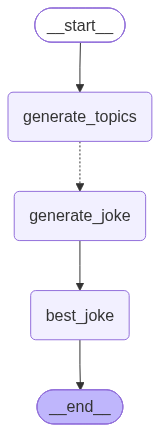

In [12]:
graph = StateGraph(OverallState)
graph.add_node("generate_joke", generate_joke)
graph.add_node("generate_topics", generate_topics)
graph.add_node("best_joke", best_joke)
graph.add_edge(START, "generate_topics")
graph.add_conditional_edges("generate_topics", continue_to_jokes, ["generate_joke"])
graph.add_edge("generate_joke", "best_joke")
graph.add_edge("best_joke", END)
app = graph.compile()
display(Image(app.get_graph().draw_mermaid_png()))

In [13]:
for s in app.stream(cast(OverallState, {"topic": "liberals"})):
    print(s)


d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(


{'generate_topics': {'subjects': ['healthcare reform', 'environmental protection', 'social equality', 'progressive social policies']}}


d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(
d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(
d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(
d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured outpu

{'generate_joke': {'jokes': ['Social equality is like a really enthusiastic buffet: everyone gets a seat, but whether you end up with the prime rib or a slightly wilted lettuce leaf is less about inherent worth and more about *who showed up first* and *who has the best networking skills to claim the extra space*.']}}
{'generate_joke': {'jokes': ["Why did the environmentalist break up with the recycling bin? Because it was too *uptight* about me not sorting my banana peels by regional acidity level. Now we're just *biodegrading* things our own way. (And the landfill is surprisingly chill.)"]}}
{'generate_joke': {'jokes': ["Healthcare reform is like trying to assemble IKEA furniture with a vague sense of 'better access.' You get the pieces, but sometimes you still end up with a complicated, slightly expensive shelf that only *almost* works, and you've spent three hours deciphering instructions written in highly bureaucratic Swedish."]}}
{'generate_joke': {'jokes': ["Progressive social po

d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(


{'best_joke': {'best_selected_joke': "Progressive social policies are like artisanal sourdough: everyone agrees it's a good idea, but sometimes I just want a piece of plain white bread and not have a TED Talk about its cultural significance."}}
